# Chapitre 5 - Lab : réplication en streaming avec PostgreSQL

Les cours 1 et 2 ont simulé un leader et ses suiveurs. Ce lab observe la même chose sur
un vrai système : un primaire PostgreSQL 16 et deux répliques alimentées par l'expédition
du WAL (*streaming replication*). On y mesure le retard de réplication, on provoque une
lecture périmée, on implémente « lire ses écritures » avec un jeton de position, on
compare les niveaux de `synchronous_commit` et on voit un suiveur synchrone bloquer les
écritures, on lit le journal logique produit par `test_decoding`, et l'on termine par un
basculement qui perd des écritures confirmées puis par un split brain.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/replication/compose.yml -p ddia_replication up -d
# ... exécuter le notebook (une seule fois : la fin modifie la topologie) ...
docker compose -f docker/replication/compose.yml -p ddia_replication down -v
```

Chaque réplique démarre par une copie de base du primaire (`pg_basebackup -R` :
instantané + position du journal, puis mode standby), exactement la recette de la
section *Setting Up New Followers*. Ports de l'hôte : primaire **10632**, `replica1`
**10633**, `replica2` **10634** (utilisateur, mot de passe et base : `ddia`).

**Plan.**

1. La topologie : un primaire, deux répliques en lecture seule.
2. Mesurer le retard de réplication.
3. Lecture périmée et « lire ses écritures » avec un jeton de LSN.
4. Réplication synchrone : coût et blocage.
5. Le journal logique.
6. Basculement : écritures perdues et split brain.

In [1]:
import subprocess
import threading
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from psycopg import errors

from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.max_colwidth", 90)
ROOT = next(d for d in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (d / "docker/replication/compose.yml").exists())
COMPOSE = ["docker", "compose", "-f", str(ROOT / "docker/replication/compose.yml"), "-p", "ddia_replication"]
PORTS = {"primary": 10632, "replica1": 10633, "replica2": 10634}
DSN = {n: f"host=localhost port={p} user=ddia password=ddia dbname=ddia connect_timeout=5" for n, p in PORTS.items()}

def compose(*args):
    return subprocess.run(COMPOSE + list(args), check=True, capture_output=True, text=True)

def q(node, sql, params=None):
    with psycopg.connect(DSN[node], autocommit=True) as c:
        cur = c.execute(sql, params)
        return cur.fetchall() if cur.description else None

def attendre(node, timeout=60):
    t0 = time.time()
    while time.time() - t0 < timeout:
        try:
            return q(node, "SELECT 1")
        except psycopg.OperationalError:
            time.sleep(0.5)
    raise RuntimeError(f"{node} injoignable")

for n in PORTS:
    attendre(n)
print(q("primary", "SELECT version()")[0][0])

PostgreSQL 16.15 on x86_64-pc-linux-musl, compiled by gcc (Alpine 15.2.0) 15.2.0, 64-bit


## 1. La topologie (section *Leaders and Followers*)

Côté primaire, la vue `pg_stat_replication` liste les suiveurs connectés, leur état et
les positions (LSN) qu'ils ont reçues, écrites sur disque et rejouées. Côté répliques,
`pg_is_in_recovery()` vaut vrai : elles rejouent le journal et refusent les écritures.

In [2]:
for _ in range(60):
    if len(q("primary", "SELECT 1 FROM pg_stat_replication")) == 2:
        break
    time.sleep(1)
display(pd.DataFrame(q("primary", """SELECT application_name, state, sync_state, sent_lsn::text, replay_lsn::text
                                      FROM pg_stat_replication ORDER BY application_name"""),
                     columns=["suiveur", "état", "mode", "LSN envoyé", "LSN rejoué"]))
display(pd.DataFrame([(n, q(n, "SELECT pg_is_in_recovery()")[0][0]) for n in PORTS],
                     columns=["nœud", "en récupération (lecture seule)"]).set_index("nœud"))
q("primary", "DROP TABLE IF EXISTS mesures; CREATE TABLE mesures (id bigserial PRIMARY KEY, v int, t timestamptz DEFAULT now())")
time.sleep(1)
try:
    q("replica1", "INSERT INTO mesures (v) VALUES (1)")
except errors.ReadOnlySqlTransaction as e:
    print("écriture sur replica1 refusée :", e.diag.message_primary)

,suiveur,état,mode,LSN envoyé,LSN rejoué
0,replica1,streaming,async,0/4000000,0/4000000
1,replica2,streaming,async,0/4000000,0/4000000


,en récupération (lecture seule)
nœud,
primary,False
replica1,True
replica2,True


écriture sur replica1 refusée : cannot execute INSERT in a read-only transaction


Les deux suiveurs sont en `streaming`, en mode `async` (réglage par défaut) ; la table
créée sur le primaire est apparue sur les répliques par le journal, et une écriture
directe sur une réplique est refusée : les suiveurs sont en lecture seule pour les
clients.

> **À retenir.** PostgreSQL réalise la réplication à leader unique par expédition du WAL ;
> `pg_stat_replication` expose, pour chaque suiveur, les positions du journal qui
> permettent de mesurer son retard.

## 2. Mesurer le retard de réplication (section *Problems with Replication Lag*)

Pour chaque écriture validée sur le primaire, on interroge `replica2` en boucle jusqu'à
voir la ligne : le délai mesuré est le retard **perçu** par un lecteur. On le fait d'abord
à vide, puis pendant qu'un autre client écrit en masse (des insertions de 200 000 lignes).

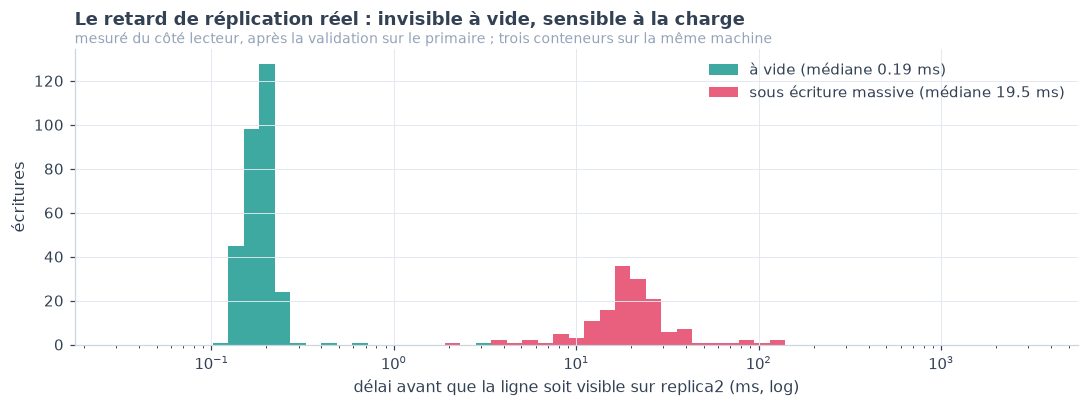

,à vide,sous charge
p50 (ms),0.19,19.48
p99 (ms),0.30,109.98
max (ms),2.83,136.71


In [3]:
def mesurer(n=200, charge=False):
    stop = threading.Event()
    def ecrivain_massif():
        with psycopg.connect(DSN["primary"], autocommit=True) as c:
            c.execute("CREATE TABLE IF NOT EXISTS lest (x int, pad text)")
            while not stop.is_set():
                c.execute("INSERT INTO lest SELECT g, repeat('x', 200) FROM generate_series(1, 200000) g")
    th = threading.Thread(target=ecrivain_massif, daemon=True)
    if charge:
        th.start(); time.sleep(1.0)
    delais = []
    with psycopg.connect(DSN["primary"], autocommit=True) as p, psycopg.connect(DSN["replica2"], autocommit=True) as r:
        for i in range(n):
            pid = p.execute("INSERT INTO mesures (v) VALUES (%s) RETURNING id", (i,)).fetchone()[0]
            t0 = time.perf_counter()
            while not r.execute("SELECT 1 FROM mesures WHERE id = %s", (pid,)).fetchone():
                pass
            delais.append((time.perf_counter() - t0) * 1000)
    stop.set()
    if charge:
        th.join()
    return np.array(delais)

a_vide = mesurer(300)
sous_charge = mesurer(150, charge=True)
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.logspace(-1.5, 3.5, 60)
ax.hist(a_vide, bins=bins, color=TEAL, alpha=0.8, label=f"à vide (médiane {np.median(a_vide):.2f} ms)")
ax.hist(sous_charge, bins=bins, color=ROSE, alpha=0.7, label=f"sous écriture massive (médiane {np.median(sous_charge):.1f} ms)")
ax.set_xscale("log"); ax.set_xlabel("délai avant que la ligne soit visible sur replica2 (ms, log)"); ax.set_ylabel("écritures")
ax.set_title("Le retard de réplication réel : invisible à vide, sensible à la charge")
subtitle(ax, "mesuré du côté lecteur, après la validation sur le primaire ; trois conteneurs sur la même machine")
ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame({"à vide": np.percentile(a_vide, [50, 99, 100]), "sous charge": np.percentile(sous_charge, [50, 99, 100])},
             index=["p50 (ms)", "p99 (ms)", "max (ms)"]).round(2)

Sur une même machine, à vide, la ligne est visible sur la réplique en une fraction de
milliseconde (souvent dès la première lecture) : c'est le cas normal du livre, un retard
imperceptible. Sous écriture massive, le journal à transmettre et à rejouer s'allonge, et
la même petite écriture attend derrière les autres (le journal se rejoue **dans
l'ordre**) : le retard grimpe de plusieurs ordres de grandeur. Le primaire mesure aussi
le retard en **octets de journal** et en temps :

In [4]:
q("primary", "INSERT INTO lest SELECT g, repeat('x', 200) FROM generate_series(1, 300000) g")
display(pd.DataFrame(q("primary", """SELECT application_name, pg_wal_lsn_diff(pg_current_wal_lsn(), replay_lsn) AS octets,
                                             write_lag, replay_lag FROM pg_stat_replication ORDER BY 1"""),
                     columns=["suiveur", "retard (octets de WAL)", "write_lag", "replay_lag"]))
q("primary", "DROP TABLE IF EXISTS lest")

,suiveur,retard (octets de WAL),write_lag,replay_lag
0,replica1,79432832,0 days 00:00:00.004635,0 days 00:00:00.004635
1,replica2,77674736,0 days 00:00:00.003585,0 days 00:00:00.003585


Juste après une grosse insertion, le retard en octets est non nul : c'est la soustraction
« position du leader moins position du suiveur » décrite dans la section *Monitoring
staleness*, que l'on surveille et sur laquelle on déclenche des alertes.

> **À retenir.** Le retard de réplication se mesure en positions de journal (octets) ou
> en temps ; négligeable à vide, il dépend de la charge d'écriture, car le suiveur rejoue
> le journal dans l'ordre.

## 3. Lecture périmée et « lire ses écritures » (section *Reading Your Own Writes*)

Pour rendre le retard visible à coup sûr, on **suspend le rejeu** du journal sur
`replica1` (`pg_wal_replay_pause()`) : la réplique continue de recevoir le journal mais ne
l'applique plus, comme un suiveur saturé. Un utilisateur écrit un commentaire sur le
primaire, puis relit.

In [5]:
q("primary", "DROP TABLE IF EXISTS commentaires; CREATE TABLE commentaires (id serial PRIMARY KEY, auteur text, texte text)")
time.sleep(0.5)
q("replica1", "SELECT pg_wal_replay_pause()")
with psycopg.connect(DSN["primary"], autocommit=True) as p:
    p.execute("INSERT INTO commentaires (auteur, texte) VALUES ('alice', 'Premier !')")
    jeton = p.execute("SELECT pg_current_wal_lsn()::text").fetchone()[0]     # position après l'écriture
print("jeton (LSN de l'écriture) :", jeton)
pd.DataFrame({"nœud": ["primary", "replica1 (rejeu suspendu)", "replica2"],
              "commentaires visibles": [q("primary", "SELECT count(*) FROM commentaires")[0][0],
                                        q("replica1", "SELECT count(*) FROM commentaires")[0][0],
                                        q("replica2", "SELECT count(*) FROM commentaires")[0][0]],
              "LSN rejoué": ["-", q("replica1", "SELECT pg_last_wal_replay_lsn()::text")[0][0],
                             q("replica2", "SELECT pg_last_wal_replay_lsn()::text")[0][0]]}).set_index("nœud")

jeton (LSN de l'écriture) : 0/7A654458


,commentaires visibles,LSN rejoué
nœud,,
primary,1,-
replica1 (rejeu suspendu),0,0/7A6542D0
replica2,1,0/7A654458


Alice ne voit pas son commentaire si sa relecture tombe sur `replica1`. Implémentons la
parade du jeton : le client garde le LSN de sa dernière écriture ; pour lire, il choisit
une réplique dont la position rejouée est au moins égale au jeton, sinon il attend un peu,
sinon il lit sur le primaire.

In [6]:
def lire_ses_ecritures(sql, jeton, repliques=("replica1", "replica2"), attente=0.2):
    for nom in repliques:
        with psycopg.connect(DSN[nom], autocommit=True) as c:
            t0 = time.time()
            while time.time() - t0 < attente:
                ok = c.execute("SELECT pg_last_wal_replay_lsn() >= %s::pg_lsn", (jeton,)).fetchone()[0]
                if ok:
                    return nom, c.execute(sql).fetchall()
                time.sleep(0.01)
    return "primary", q("primary", sql)

for ordre in [("replica1", "replica2"), ("replica1",)]:
    noeud, res = lire_ses_ecritures("SELECT auteur, texte FROM commentaires", jeton, ordre)
    print(f"répliques candidates {ordre} -> lecture servie par {noeud} : {res}")
q("replica1", "SELECT pg_wal_replay_resume()")
time.sleep(0.5)
print("après reprise du rejeu, replica1 voit :", q("replica1", "SELECT count(*) FROM commentaires")[0][0], "commentaire(s)")

répliques candidates ('replica1', 'replica2') -> lecture servie par replica2 : [('alice', 'Premier !')]


répliques candidates ('replica1',) -> lecture servie par primary : [('alice', 'Premier !')]


après reprise du rejeu, replica1 voit : 1 commentaire(s)


Avec les deux répliques candidates, la lecture est servie par `replica2`, à jour ; si
seule `replica1` est candidate, elle échoue à atteindre le jeton dans le délai et la
lecture part au primaire. Dans les deux cas, Alice voit son commentaire. Une fois le rejeu
repris, `replica1` rattrape instantanément (elle avait reçu le journal, elle ne l'appliquait
plus).

> **À retenir.** Un jeton de LSN suffit à garantir « lire ses écritures » sur PostgreSQL :
> `pg_current_wal_lsn()` après l'écriture, `pg_last_wal_replay_lsn()` sur la réplique.